# Basics 1 — What a convolution is

Every example uses the same Playmobil photos: 11 DC characters × 9 arm positions × 8 viewing angles.

**What is mechanistic interpretability?** A trained network is a pile of numbers (its *weights*) that
turns an image into an answer. Mechanistic interpretability tries to explain *how*: which intermediate
signals the network computes, what each one responds to, and how later signals are built from earlier ones.
To do that we need to know exactly what each layer computes. For a convolutional network (CNN), the
basic operation is the **convolution**, so we start there. This notebook trains nothing: we write filters
by hand and look at what they do.

**Tensor shapes.** We print the shape of every tensor we create. Images in PyTorch are stored as
**`[B, C, H, W]`**:

| letter | meaning | example |
|---|---|---|
| `B` | batch: how many images | 792 for the whole dataset, 1 for one image |
| `C` | channels: numbers per pixel | 3 for an RGB photo (red, green, blue); later, one per filter |
| `H`, `W` | height and width in pixels | 96 × 96 for our CNN |

Reading shapes aloud helps: `[4, 3, 96, 96]` is "4 images, 3 colour channels, 96 × 96 pixels".

**Contents**
1. An image is a tensor
2. A convolution by hand, on 6 × 6 real pixels
3. Hand-made filters on a whole image: blur and edges
4. Padding and stride: predicting the output shape
5. Filters that read colour (3 input channels)
6. Many filters at once: `nn.Conv2d`
7. Exercises

In [3]:
# Setup: on Colab this installs the package from GitHub; locally run `uv pip install -e .` in the repo first.
import sys
if "google.colab" in sys.modules:
    !pip install -q git+https://github.com/nicolascortegoso/vision-interp-playground.git

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from visinterp import *
from visinterp.analysis import *
from visinterp.plotting import heatmap, show_images

plt.rcParams["figure.dpi"] = 90
data = load_dataset()  # downloads ~200 MB and preprocesses on the first run, then loads from cache
device = get_device()
print(f"{len(data)} images, device: {device}")

792 images, device: mps


## 1. An image is a tensor

`data.images` holds all 792 photos as integers from 0 to 255. Our small CNNs work on 96 × 96 images with
values from 0 to 1, which `data.float_images(96)` returns.

data.images: (792, 3, 224, 224) torch.uint8   # [B, C, H, W] = 792 photos, RGB, 224x224
x_all:       (792, 3, 96, 96) torch.float32   # resized to 96x96, values in [0, 1]
img:         (3, 96, 96)   # one image: [C, H, W], no batch dimension
top-left pixel (background) RGB = [1.0, 1.0, 1.0]  -> white is (1, 1, 1)


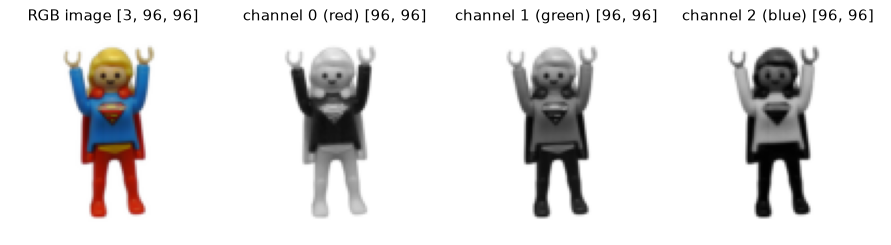

In [5]:
print("data.images:", tuple(data.images.shape), data.images.dtype, "  # [B, C, H, W] = 792 photos, RGB, 224x224")

x_all = data.float_images(96)
print("x_all:      ", tuple(x_all.shape), x_all.dtype, "  # resized to 96x96, values in [0, 1]")

i = data.index(character="supergirl", arm_position="both_up", angle=0)[0]
img = x_all[i]
print("img:        ", tuple(img.shape), "  # one image: [C, H, W], no batch dimension")
print(f"top-left pixel (background) RGB = {img[:, 0, 0].tolist()}  -> white is (1, 1, 1)")

fig, axes = plt.subplots(1, 4, figsize=(10, 2.8))
axes[0].imshow(img.permute(1, 2, 0))  # matplotlib wants [H, W, C], so we move C to the end
axes[0].set_title("RGB image [3, 96, 96]")
for c, name in enumerate(["red", "green", "blue"]):
    axes[c + 1].imshow(img[c], cmap="gray", vmin=0, vmax=1)
    axes[c + 1].set_title(f"channel {c} ({name}) [96, 96]")
for ax in axes:
    ax.axis("off")
plt.tight_layout()

Each colour channel is a 96 × 96 grid of numbers. The white background is bright (≈1) in all three.
Supergirl's red skirt and boots are bright in the red channel and dark in green and blue; her blue top is
the opposite. Colour is not stored anywhere as a single number: it is the *pattern across channels* at
each pixel.

Many examples below use a grayscale version, made by averaging the three channels. We keep a channel
dimension of size 1, because convolution functions always expect `[B, C, H, W]`.

In [6]:
gray = img.mean(dim=0, keepdim=True)  # average over C
print("gray:        ", tuple(gray.shape), "  # [C=1, H, W]")
gray_b = gray.unsqueeze(0)  # add a batch dimension
print("gray_b:      ", tuple(gray_b.shape), "  # [B=1, C=1, H, W], the layout conv functions expect")

gray:         (1, 96, 96)   # [C=1, H, W]
gray_b:       (1, 1, 96, 96)   # [B=1, C=1, H, W], the layout conv functions expect


## 2. A convolution by hand

A convolution slides a small grid of weights, the **kernel** (or **filter**), over the image. At each
position it multiplies the kernel with the patch of pixels under it, element by element, and adds
everything up. That sum is one output pixel.

We take a real 6 × 6 patch where the figure meets the white background, and this 3 × 3 kernel:

```
-1  0  +1
-2  0  +2
-1  0  +1
```

It computes "right side minus left side" (with extra weight on the middle row). This is the
*Sobel* filter for **vertical edges**: on a flat area the two sides cancel and the output is 0; where
brightness changes from left to right the output is large.

In [7]:
# Find a patch that contains the figure's left outline: on the middle row, the first pixel that is not white.
row = 48
col = int((gray[0, row] < 0.9).nonzero()[0])
patch = gray[0, row - 3 : row + 3, col - 3 : col + 3]
print("patch:", tuple(patch.shape), " # [H, W] = 6x6 pixels, the left part is white background")
print(patch.numpy().round(2))

sobel_x = torch.tensor([[-1.0, 0.0, 1.0],
                        [-2.0, 0.0, 2.0],
                        [-1.0, 0.0, 1.0]])
print("\nsobel_x:", tuple(sobel_x.shape), " # [kH, kW]")

patch: (6, 6)  # [H, W] = 6x6 pixels, the left part is white background
[[1.   1.   1.   0.73 0.21 0.14]
 [1.   1.   1.   0.72 0.21 0.14]
 [1.   1.   1.   0.71 0.21 0.14]
 [1.   1.   1.   0.7  0.21 0.14]
 [1.   1.   1.   0.69 0.21 0.14]
 [1.   1.   1.   0.69 0.21 0.15]]

sobel_x: (3, 3)  # [kH, kW]


In [8]:
k = 3
H, W = patch.shape
out = torch.zeros(H - k + 1, W - k + 1)  # the kernel fits in 6 - 3 + 1 = 4 positions per direction
for r in range(H - k + 1):
    for c in range(W - k + 1):
        window = patch[r : r + k, c : c + k]  # [3, 3] pixels under the kernel
        out[r, c] = (window * sobel_x).sum()  # multiply element-wise, then add up
print("out (by hand):", tuple(out.shape), " # [4, 4]: smaller than the input, the kernel never leaves the patch")
print(out.numpy().round(2))

out (by hand): (4, 4)  # [4, 4]: smaller than the input, the kernel never leaves the patch
[[-0.01 -1.13 -3.16 -2.32]
 [-0.01 -1.17 -3.16 -2.28]
 [-0.01 -1.2  -3.16 -2.24]
 [-0.01 -1.22 -3.16 -2.2 ]]


The output is strongly **negative** where the bright background on the left meets the darker figure
on the right ("right minus left" < 0), and near 0 elsewhere.

PyTorch does the same with `F.conv2d`. It wants the input as `[B, C_in, H, W]` and the kernel as
**`[C_out, C_in, kH, kW]`**: one kernel per output channel, and each kernel has a slice for every input
channel. Here there is 1 input channel and 1 output channel.

In [9]:
import torch.nn.functional as F

inp = patch[None, None]  # [6, 6] -> [1, 1, 6, 6]
weight = sobel_x[None, None]  # [3, 3] -> [1, 1, 3, 3]
out_torch = F.conv2d(inp, weight)
print("input :", tuple(inp.shape), "  # [B, C_in, H, W]")
print("weight:", tuple(weight.shape), "  # [C_out, C_in, kH, kW]")
print("output:", tuple(out_torch.shape), "  # [B, C_out, H_out, W_out]")
print("same as the loop:", torch.allclose(out_torch[0, 0], out, atol=1e-6))

input : (1, 1, 6, 6)   # [B, C_in, H, W]
weight: (1, 1, 3, 3)   # [C_out, C_in, kH, kW]
output: (1, 1, 4, 4)   # [B, C_out, H_out, W_out]
same as the loop: True


> **Note.** Mathematicians would call this *cross-correlation*: a "true" convolution flips the kernel
> first. Deep-learning libraries skip the flip and still call it convolution. It makes no difference for
> learned kernels, but it explains why a "right minus left" kernel has its `+` weights on the right.

## 3. Hand-made filters on a whole image

The same idea on the full 96 × 96 image, with three kernels at once. Stacking them gives a weight of
shape `[3, 1, 3, 3]`: 3 output channels, each reading the 1 grayscale input channel.

- **blur**: all weights 1/9, the average of the 3 × 3 neighbourhood;
- **vertical edges** (`sobel_x`): right minus left;
- **horizontal edges** (`sobel_y` = `sobel_x` transposed): bottom minus top.

`padding=1` adds a 1-pixel border of zeros around the image, so the output keeps the size 96 × 96
(section 4 explains why).

input  gray_b: (1, 1, 96, 96)  # [1, 1, 96, 96]
weight       : (3, 1, 3, 3)   # [3, 1, 3, 3]
maps         : (1, 3, 96, 96)  # [1, 3, 96, 96]: one 96x96 map per kernel


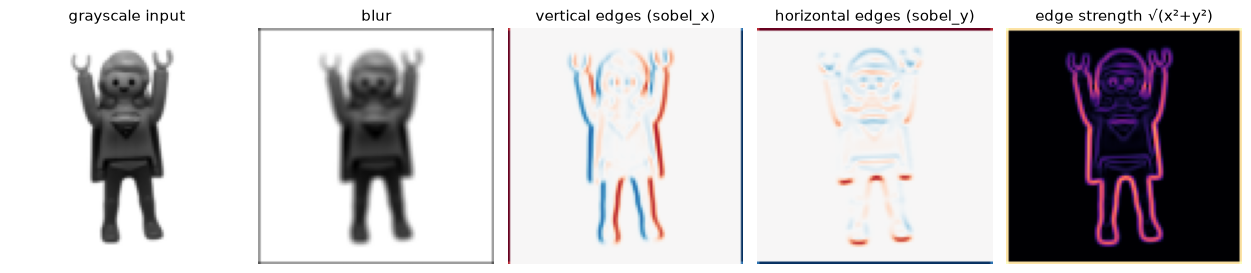

In [25]:
blur = torch.full((3, 3), 1 / 9)
sobel_y = sobel_x.T
kernels = torch.stack([blur, sobel_x, sobel_y])  # [3, 3, 3]
weight = kernels[:, None]  # [C_out=3, C_in=1, 3, 3]
maps = F.conv2d(gray_b, weight, padding=1)
print("input  gray_b:", tuple(gray_b.shape), " # [1, 1, 96, 96]")
print("weight       :", tuple(weight.shape), "  # [3, 1, 3, 3]")
print("maps         :", tuple(maps.shape), " # [1, 3, 96, 96]: one 96x96 map per kernel")

edge_strength = (maps[0, 1] ** 2 + maps[0, 2] ** 2).sqrt()  # [96, 96]

fig, axes = plt.subplots(1, 5, figsize=(14, 3))
axes[0].imshow(gray[0], cmap="gray"); axes[0].set_title("grayscale input")
axes[1].imshow(maps[0, 0], cmap="gray"); axes[1].set_title("blur")
lim = maps[0, 1:].abs().max()
axes[2].imshow(maps[0, 1], cmap="RdBu_r", vmin=-lim, vmax=lim); axes[2].set_title("vertical edges (sobel_x)")
axes[3].imshow(maps[0, 2], cmap="RdBu_r", vmin=-lim, vmax=lim); axes[3].set_title("horizontal edges (sobel_y)")
axes[4].imshow(edge_strength, cmap="magma"); axes[4].set_title("edge strength √(x²+y²)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()

Red means positive output, blue negative. The vertical-edge map lights up on the left and right
outlines of the figure, with **opposite signs** on the two sides (bright→dark versus dark→bright). The
horizontal-edge map lights up on the top of the head, the shoulders and the hands. Combining the two
gives the full outline.

Notice the frame around the blur and edge maps. `padding=1` pads with **zeros**, which is black, next to a
white background. The kernel sees a fake black-to-white edge at the border of the image. Real CNNs have
the same artefact; keep it in mind when a feature map lights up along the image border.

This is the key idea for the rest of the track: **a filter is a pattern detector**. Its output is large
where the image locally looks like the kernel. A CNN *learns* its kernels instead of us writing them,
and the next notebook checks whether a trained network learns anything like these.

## 4. Padding and stride: predicting the output shape

Two settings control the output size:

- **padding `p`**: extra pixels (zeros) added around the border before sliding the kernel;
- **stride `s`**: how many pixels the kernel jumps between positions (1 = every position, 2 = every other).

For an input of size `H` and a kernel of size `k`:

$$H_{out} = \left\lfloor \frac{H + 2p - k}{s} \right\rfloor + 1$$

The by-hand example above was `H=6, k=3, p=0, s=1` → (6 + 0 − 3) / 1 + 1 = **4**. With `p = (k−1)/2`
and `s = 1` (as in section 3) the size stays the same. That "same" setting is what our CNN uses.

In [26]:
def out_size(H, k, p, s):
    return (H + 2 * p - k) // s + 1

rows = []
for k, p, s in [(3, 0, 1), (3, 1, 1), (5, 2, 1), (5, 0, 1), (3, 1, 2), (5, 2, 2), (7, 3, 4)]:
    w = torch.zeros(1, 1, k, k)
    y = F.conv2d(gray_b, w, padding=p, stride=s)
    rows.append({"k": k, "padding": p, "stride": s, "formula": out_size(96, k, p, s), "F.conv2d output": tuple(y.shape)})
pd.DataFrame(rows)

,k,padding,stride,formula,F.conv2d output
0,3,0,1,94,"(1, 1, 94, 94)"
1,3,1,1,96,"(1, 1, 96, 96)"
2,5,2,1,96,"(1, 1, 96, 96)"
3,5,0,1,92,"(1, 1, 92, 92)"
4,3,1,2,48,"(1, 1, 48, 48)"
5,5,2,2,48,"(1, 1, 48, 48)"
6,7,3,4,24,"(1, 1, 24, 24)"


The formula matches PyTorch in every row. Stride 2 halves the size, which is one way to make the maps
smaller as the network gets deeper. Our CNN uses **max pooling** for that instead (Basics 3).

## 5. Filters that read colour

With an RGB input, `C_in = 3` and every kernel has one slice per colour channel: shape `[C_out, 3, kH, kW]`.
The output at a pixel is the sum over **all three channels** of the window. So one filter can respond to
a *combination* of colours.

The simplest case is a **1 × 1 kernel**: no neighbourhood at all, just a weighted mix of R, G, B at each
pixel. A "redness" filter: `R − (G + B)/2`. White gives 1 − 1 = 0, gray gives 0, pure red gives 1.

x4      : (4, 3, 96, 96)  # 4 images
redness : (1, 3, 1, 1)
r       : (4, 1, 96, 96)  # [4, 1, 96, 96]: one redness map per image


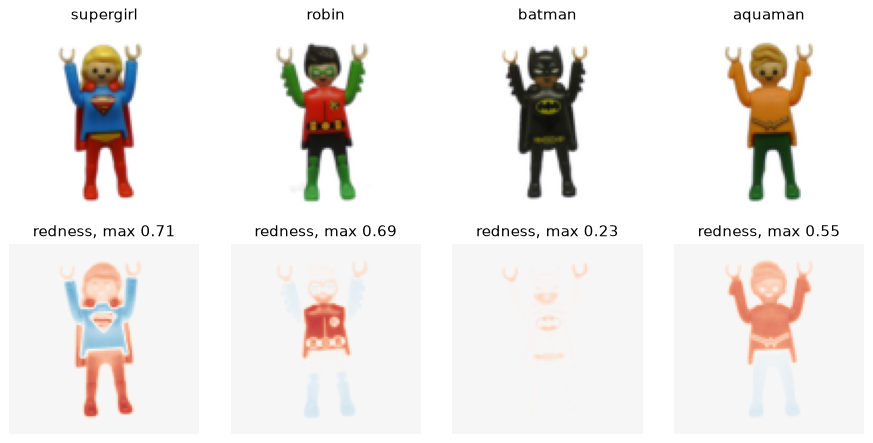

In [27]:
redness = torch.tensor([1.0, -0.5, -0.5]).view(1, 3, 1, 1)  # [C_out=1, C_in=3, 1, 1]
names = ["supergirl", "robin", "batman", "aquaman"]
x4 = x_all[[data.index(character=n, arm_position="both_up", angle=0)[0] for n in names]]
r = F.conv2d(x4, redness)
print("x4      :", tuple(x4.shape), " # 4 images")
print("redness :", tuple(redness.shape))
print("r       :", tuple(r.shape), " # [4, 1, 96, 96]: one redness map per image")

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for j, n in enumerate(names):
    axes[0, j].imshow(x4[j].permute(1, 2, 0)); axes[0, j].set_title(n)
    axes[1, j].imshow(r[j, 0], cmap="RdBu_r", vmin=-1, vmax=1); axes[1, j].set_title(f"redness, max {r[j, 0].max():.2f}")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()

The filter finds Supergirl's skirt, cape and boots and Robin's red tunic, and ignores the white background
and Batman's black and grey. It goes negative (blue) on Supergirl's blue top and Robin's green sleeves.
It also fires on Aquaman's **orange** top: orange has much more red than green and blue, so by this
formula it counts as "red". A filter detects whatever matches its weights, not the concept we had in mind
when we wrote it. The same caution applies to every learned filter in the next notebooks.

A single number per pixel already separates some characters: **colour is a strong cue in this dataset**,
and the trained network relies on it a lot.

## 6. Many filters at once: `nn.Conv2d`

A convolutional **layer** is a stack of filters plus one **bias** per filter (a constant added to its
output). `nn.Conv2d(3, 8, kernel_size=5, padding=2)` holds 8 filters of shape `[3, 5, 5]`:

- `weight`: `[8, 3, 5, 5]` → 8 × 3 × 5 × 5 = 600 numbers,
- `bias`: `[8]` → 8 numbers.

Its output has **one channel per filter**: `[B, 3, 96, 96]` in, `[B, 8, 96, 96]` out. The channels of a
layer's output are often called **feature maps**. This is exactly the first layer of the CNN in the next
notebook. Here it is untrained, with random weights.

weight: (8, 3, 5, 5)  # [C_out, C_in, kH, kW]
bias  : (8,)
parameters: 608 = 8*3*5*5 + 8
input : (4, 3, 96, 96)
output: (4, 8, 96, 96)  # 8 feature maps per image


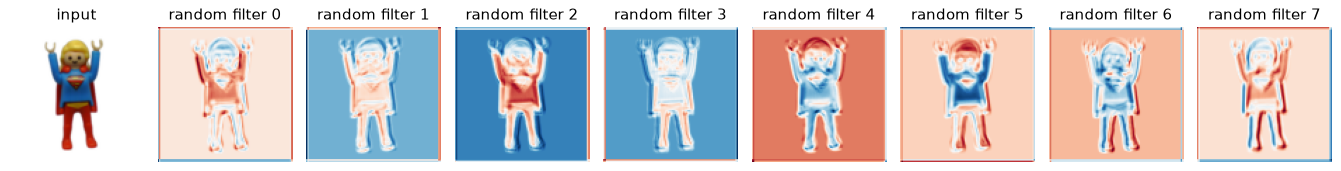

In [33]:
torch.manual_seed(0)
layer = torch.nn.Conv2d(in_channels=3, out_channels=8, kernel_size=5, padding=2)
print("weight:", tuple(layer.weight.shape), " # [C_out, C_in, kH, kW]")
print("bias  :", tuple(layer.bias.shape))
print("parameters:", sum(p.numel() for p in layer.parameters()), "= 8*3*5*5 + 8")
with torch.no_grad():
    fmap = layer(x4)
print("input :", tuple(x4.shape))
print("output:", tuple(fmap.shape), " # 8 feature maps per image")

fig, axes = plt.subplots(1, 9, figsize=(15, 2))
axes[0].imshow(x4[0].permute(1, 2, 0)); axes[0].set_title("input")
for c in range(8):
    axes[c + 1].imshow(fmap[0, c], cmap="RdBu_r"); axes[c + 1].set_title(f"random filter {c}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()

Even random filters produce recognisable maps: each is some random mix of colours and of the
neighbourhood, so it still responds to the outline and the colour patches. Training will adjust the 608
numbers so the maps become *useful* for telling characters and poses apart.

## 7. Exercises

Write your answer in the empty cell under each exercise, then open the solution to compare.

**Exercise 1 — a diagonal edge.** Write a 3 × 3 kernel that responds to edges running diagonally (from
top-left to bottom-right), apply it to `gray_b` with `padding=1`, and plot the result. Where on the figure
is it strongest?

<details><summary>Solution</summary>

"Bottom-left minus top-right" responds to a diagonal edge from top-left to bottom-right:

```python
diag = torch.tensor([[ 0., -1., -2.],
                     [ 1.,  0., -1.],
                     [ 2.,  1.,  0.]])
d = F.conv2d(gray_b, diag[None, None], padding=1)   # [1, 1, 96, 96]
lim = d.abs().max()
plt.imshow(d[0, 0], cmap="RdBu_r", vmin=-lim, vmax=lim); plt.axis("off")
```

The map still shows most of the outline: a vertical or horizontal edge is partly diagonal, so it still
gets a sizeable response, with a sign that depends on the side. Edge filters are *tuned* to an
orientation: they prefer it without ignoring the others. A later notebook measures such tuning curves
for learned filters.
</details>

**Exercise 2 — predict the shape.** Without running anything, what is the output shape of
`F.conv2d(x4, torch.zeros(6, 3, 5, 5), stride=2)`? Then run it to check.

<details><summary>Solution</summary>

Batch 4 and 6 output channels (one per filter). Size: ⌊(96 + 0 − 5) / 2⌋ + 1 = ⌊45.5⌋ + 1 = 46.
So **`[4, 6, 46, 46]`**.

```python
F.conv2d(x4, torch.zeros(6, 3, 5, 5), stride=2).shape   # torch.Size([4, 6, 46, 46])
```
</details>

**Exercise 3 — a yellow detector.** Black Adam has a yellow lightning-bolt emblem, belt and boots. Write a
1 × 1 filter (shape `[1, 3, 1, 1]`) that is high for yellow (red and green high, blue low) and about 0 for
white, and apply it to a Black Adam image. Which other colour also gets a positive response?

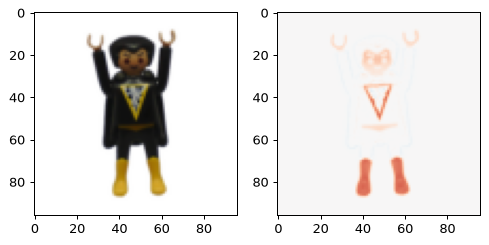

In [45]:
# youcode here

<details><summary>Solution</summary>

Yellow is `(1, 1, 0)`-ish, white is `(1, 1, 1)`. The mix `(R + G)/2 − B` gives 1 for yellow and 0 for white:

```python
yellowness = torch.tensor([0.5, 0.5, -1.0]).view(1, 3, 1, 1)
j = data.index(character="blackadam", arm_position="both_up", angle=0)[0]
yb = F.conv2d(x_all[j : j + 1], yellowness)                 # [1, 1, 96, 96]
fig, axes = plt.subplots(1, 2)
axes[0].imshow(x_all[j].permute(1, 2, 0))
axes[1].imshow(yb[0, 0], cmap="RdBu_r", vmin=-1, vmax=1)
```

The boots and the yellow outline of the emblem light up, and so does the face (skin tones are yellowish).
Pure red `(1, 0, 0)` also gives 0.5: a 1 × 1 filter only sees one
weighted sum, so it cannot fully separate every pair of colours. Several filters together can, and that
is one reason layers have many channels.
</details>

## Summary

- An image is a `[C, H, W]` tensor; a batch is `[B, C, H, W]`.
- A convolution slides a kernel over the image and computes a weighted sum at each position. Its weight
  has shape `[C_out, C_in, kH, kW]`, and its output has one channel per filter: `[B, C_out, H_out, W_out]`.
- `H_out = ⌊(H + 2p − k)/s⌋ + 1`; with `p = (k−1)/2` and `s = 1` the size is unchanged.
- A filter is a pattern detector: hand-made kernels find blur, vertical and horizontal edges, or a colour.

**Next:** Basics 2 trains a small CNN on these photos and asks what its first layer learned.